# Tail experiments: an FWM tail trained with every error channel on

**Question (user, 2026-11-11 and 2026-11-12).** Take the best FWM tail of `FWM_tails.ipynb`: the 0.8 μs tail after the
EsT X gate, trained with the decay set only. Train it again with **all of Shirol's error channels** on. Then score
gate + tail against the gate alone, also with all channels on. Does the tail beat the gate alone (break even)?

The first attempt warm-started from the decay-trained tails and found nothing new (Appendix A). This notebook now reports
the second attempt: **ten training runs from random noise, with the derivative (smoothness) penalty 10 times weaker,
1000 iterations each.**

## Setup

**The code.** Shirol's odd kitten code: $|0_L\rangle = (|1\rangle + |5\rangle)/\sqrt2$, $|1_L\rangle = |3\rangle$. One photon
loss turns the code words into *error words* with an even photon number, which the tail can repair.

**The chip.** Shirol et al., PRX 16, 021042, Table I (`AQEC/device.py`). States $|n, j, m\rangle$ = storage photons ×
transmon (g, e, f) × readout photons. The higher-order terms (storage Kerr, $\chi'$) are on everywhere.

**The gate.** The EsT X gate of `FWM_tails.ipynb` (seed 24 of the $C_{\rm err}$ cost, `u_X_est_err_closed_s24.npy`), 1.1 μs
on a 2 ns grid. It is not retrained here. It runs at storage truncation $n_c = 24$, and its output is cut to $n_c = 16$
for the tail, as in all earlier tail training.

**The tail.** 0.8 μs in which only the two FWM combs act (linear drives off). Each comb is one complex waveform
$\eta_c(t)$, capped at $|\eta_c| \le 0.1$. Method, frame and cost are those of `FWM_tails.ipynb` §4. Two things are new:
the list of jump operators (§2), and the weight of the derivative penalty (§4).

**Words and symbols.**

| term | meaning |
|---|---|
| tail | the time after the gate in which only the two FWM combs act |
| comb 1, comb 2 | comb 1 puts a lost photon back and lifts the transmon $g \to f$; comb 2 moves that excitation into the readout, which leaks it away |
| $\eta_c(t)$ | the control: one complex waveform per comb $c$, capped at $\lvert\eta_c\rvert \le 0.1$ |
| $F_{\rm pro}$ | process fidelity on the code against the ideal X gate, readout traced out. Gains in % are percentage points of $F_{\rm pro}$ |
| gain | $F_{\rm pro}$(gate + tail) − $F_{\rm pro}$(gate alone), both scored with the same noise |
| decay set | photon loss $\kappa_a$, readout decay $\kappa_r$, transmon decay $T_1$ ($e\to g$, $f \to e$): what every earlier tail was trained with |
| Shirol full set | the decay set plus transmon heating ($g\to e$, $e \to f$, with the pumps' extra heating), storage heating, and pure dephasing of transmon and storage. `AQEC/master_equation.collapse_operators` default; `noise="shirol"` in `DGRAPE` |
| DGRAPE all_ch | the older "all channels" set of `FWM_tails.ipynb` §6.5: dephasing + heating, but no $e\to f$ heating, no pump heating and the full storage dephasing |
| derivative penalty | the smoothness term of the training cost, weight × $\sum_t \lvert\eta(t+dt) - \eta(t)\rvert^2$ (the sum is called the roughness here) |
| noise start, seed | a training run that starts from small random waveforms ($\lvert\eta\rvert \approx 0.005$); the seed fixes the random numbers |
| warm-start tail | the first attempt (Appendix A): the decay-trained tail, retrained under the Shirol set at the old weight. It returned its start unchanged |
| QEC teeth | Shirol's Table II comb strengths held constant: a fixed reference tail |
| idle | the gate followed by 0.8 μs of nothing: what waiting costs |
| $n_c$ | number of storage Fock levels kept in the simulation |

In [1]:
import json
import os
import sys

if os.path.basename(os.path.abspath(".")) == "notebooks":   # the notebook lives in notebooks/; data paths are relative to the repo root
    os.chdir("..")
REPO_ROOT = os.path.abspath(".")
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from joblib import Parallel, delayed

from AQEC import master_equation as me
from DGRAPE import fwm
from DGRAPE import fwm_tail as ft
from DGRAPE.model import rates as dgrape_rates

np.seterr(divide="ignore", over="ignore", invalid="ignore")

DT = ft.DT
TAIL_US = 0.8
GATE = "pulses/dgrape/u_X_est_err_closed_s24.npy"       # the EsT X gate ("EsT-good", seed 24), 1.1 us
SEEDS = list(range(1, 11))
COLD = {f"seed {s}": f"X_tail_estg_T08_shirol_d01_s{s}" for s in SEEDS}     # this notebook's sweep
WARM = {"warm t2": "X_tail_estg_T08_shirol_t2", "warm z": "X_tail_estg_T08_shirol_z"}   # Appendix A
DECAY = {"decay t2": "X_tail_estg_T08_t2", "decay z": "X_tail_estg_T08_z"}           # FWM_tails.ipynb
LABEL = {v: k for k, v in {**COLD, **WARM, **DECAY}.items()}
W_OLD = ft.TAIL_PENALTIES["deriv"]                         # 0.625, the weight of every earlier tail
OKABE = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00", "#56B4E9"]
os.makedirs("figures", exist_ok=True)


def tidy(ax, grid=True):
    if grid:
        ax.grid(color="0.9", lw=0.6)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)


def load_run(tag):
    with open(f"pulses/dgrape/{tag}.json") as f:
        return json.load(f), np.load(f"pulses/dgrape/eta_{tag}.npy")


RUNS = {label: load_run(tag) for label, tag in {**COLD, **WARM, **DECAY}.items()}
print({label: f"{info['F_pro']:.6f}" for label, (info, _) in RUNS.items()})

{'seed 1': '0.961215', 'seed 2': '0.961224', 'seed 3': '0.961218', 'seed 4': '0.960478', 'seed 5': '0.961096', 'seed 6': '0.961210', 'seed 7': '0.961170', 'seed 8': '0.961235', 'seed 9': '0.961209', 'seed 10': '0.961210', 'warm t2': '0.960364', 'warm z': '0.960326', 'decay t2': '0.970272', 'decay z': '0.970242'}


## 1. The question and the two rules

The earlier tails were trained with the decay set. Under it the best one (0.8 μs) gains **+0.32 %** over the gate alone
(`FWM_tails.ipynb` §6). With all of Shirol's channels on, the same tail keeps only **+0.044 %** (§3 below). Retraining it
under the Shirol set from where it was (Appendix A) changed nothing: the optimizer only smoothed the waveforms, which
the derivative penalty rewards, and lowered $F_{\rm pro}$ doing so.

That leaves two reasons why it could not improve: the start (one solution, already balanced against the old penalty), and
the derivative penalty itself. This sweep removes both at once. Each run **starts from small random waveforms** (noise
0.005, as the decay-trained zero start), **the derivative weight is 10 times smaller** (0.0625 instead of 0.625), and each
run trains for **1000 iterations** with the Shirol set on.

**Break-even rule (fixed before training, unchanged).** The tail breaks even if

$$\text{gain} = F_{\rm pro}(\text{gate + tail}) - F_{\rm pro}(\text{gate alone}) > 0$$

with the Shirol full set on in both, **both** at the training truncation ($n_c = 16$, gate output cut from 24) **and**
held out at $n_c = 28$ (gate and tail both run there, no cut), for the best run. The spread over the runs is reported
next to it.

**Seed rule (fixed before training, user 2026-11-12).** Train seeds 1–5. If their $F_{\rm pro}$ (Shirol set, $n_c = 16$,
returned tail) differs by more than 0.01 % from best to worst, train seeds 6–10 with the same settings.

## 2. The noise model

Table 1 lists every jump operator. "Shirol full set" is what we train and score with. It differs from DGRAPE's older
`all_ch` set in three ways:

- **Heating on $e \to f$** as well as $g \to e$, at the same up/down ratio.
- **Pump-driven heating.** Shirol's App. D measures an extra $\Delta\gamma_\uparrow = 0.42$ ms⁻¹ while the pumps are on. It
  is applied everywhere, during the gate as well as the tail (user decision), so the gate-alone reference pays it too.
- **Residual storage dephasing.** Thermal jumps of the transmon already dephase the storage through $\chi$. So the separate
  storage dephasing is only the residual $1/T_{2a} - \kappa_a/2 - \gamma_\uparrow^{\rm th}$ = 0.23 ms⁻¹, not the full 0.58 ms⁻¹
  (`all_ch` counts that part twice).

Every operator moves one state to one state. So the fast exact propagator (`DGRAPE/model.py`) works unchanged. The
tail's frame, which rotates only $|f\rangle$, also stays exact: $|f\rangle\langle e|$ only picks up a global phase in it
(tested in `validation/test_fwm_tail.py`, class `ShirolNoise`).

In [2]:
# Every rate, in 1/ms (Table I -> jump operators). "-" = channel not in that set.
Rd, Rs = dgrape_rates(), me.jump_rates()
ms = 1e3
rows = [
    ("storage photon loss", "a", Rd["kappa_a"], Rd["kappa_a"], Rd["kappa_a"]),
    ("readout decay", "r", Rd["kappa_r"], Rd["kappa_r"], Rd["kappa_r"]),
    ("transmon decay e->g", "|g⟩⟨e|", Rd["gamma_ge"], Rd["gamma_ge"], Rd["gamma_ge"]),
    ("transmon decay f->e", "|e⟩⟨f|", Rd["gamma_ef"], Rd["gamma_ef"], Rd["gamma_ef"]),
    ("transmon heating g->e", "|e⟩⟨g|", None, Rd["up_q"], Rs["up_ge"]),
    ("transmon heating e->f", "|f⟩⟨e|", None, None, Rs["up_ef"]),
    ("storage heating", "a'", None, Rd["up_a"], Rs["up_a"]),
    ("transmon dephasing g-e", "|e⟩⟨e|", None, Rd["phi_ge"], Rs["phi_ge"]),
    ("transmon dephasing g-f", "|f⟩⟨f|", None, Rd["phi_gf"], Rs["phi_gf"]),
    ("storage dephasing", "n_a", None, Rd["phi_a"], Rs["phi_a"]),
]
fmt = lambda v: "-" if v is None else (f"{v * ms:.3g}" if v * ms < 100 else f"{v * ms:.4g}")  # noqa: E731
table1 = pd.DataFrame([(n, op, fmt(a), fmt(b), fmt(c)) for n, op, a, b, c in rows],
                      columns=["channel", "jump operator", "decay set", "DGRAPE all_ch", "Shirol full set (this notebook)"])
display(table1.style.hide(axis="index"))
print(f"up/down ratio r: thermal {Rs['r_thermal']:.4f}, with the pumps' extra heating {Rs['r']:.4f}")

channel,jump operator,decay set,DGRAPE all_ch,Shirol full set (this notebook)
storage photon loss,a,7.35,7.35,7.35
readout decay,r,3644,3644,3644
transmon decay e->g,|g⟩⟨e|,20,20,20
transmon decay f->e,|e⟩⟨f|,32.3,32.3,32.3
transmon heating g->e,|e⟩⟨g|,-,0.346,0.766
transmon heating e->f,|f⟩⟨e|,-,-,1.24
storage heating,a',-,0.0444,0.0444
transmon dephasing g-e,|e⟩⟨e|,-,8.87,8.87
transmon dephasing g-f,|f⟩⟨f|,-,17.2,17.2
storage dephasing,n_a,-,0.579,0.233


up/down ratio r: thermal 0.0173, with the pumps' extra heating 0.0383


**Table 1.** Jump rates in ms⁻¹ for the three noise sets. The Shirol column is built from `AQEC.master_equation.jump_rates()`.
It is tested equal, operator for operator, to `AQEC.master_equation.collapse_operators` at $n_c = 8$ (to 1e-12).
The decay set is the default of every earlier DGRAPE run and every earlier tail. Heating sits far below decay; dephasing
is about half of transmon $T_1$.
*Symbols:* $a$ storage lowering, $r$ readout lowering, $n_a = a^\dagger a$; "-" = channel absent; $r$ (printed below the
table) = transmon up/down rate ratio.

## 3. Before training: what the decay-trained tails already do

Before training, every reference and the two decay-trained tails are scored under all three noise sets (Table 2). This
is the number training under the Shirol set has to beat.

In [3]:
# Forward scores before any training (cached). The gate runs at n_c 24 and is cut to 16, as in training.
CACHE3 = "tables/tail_experiments_baselines.csv"
if not os.path.exists(CACHE3):
    pulse = np.load(GATE)
    N = ft.n_steps(TAIL_US)
    etas = {"gate alone": np.zeros((0, 2), complex), "gate + idle 0.8 us": np.zeros((N, 2), complex),
            "gate + QEC teeth 0.8 us": ft.eta_from_teeth(fwm.beta_table2(ft.REPAIR_PATHS), N, DT, 16),
            "gate + decay tail (t2)": RUNS["decay t2"][1], "gate + decay tail (z)": RUNS["decay z"][1]}
    conds = {"decay": {}, "DGRAPE all_ch": {"dephasing": True, "heating": True}, "Shirol full set": {"noise": "shirol"}}

    def _one(case, cond):
        return {"case": case, "channels": cond,
                "F_pro": ft.score(etas[case], n_c=16, gate_n_c=24, pulse=pulse, **conds[cond])["F_pro"]}

    pd.DataFrame(Parallel(n_jobs=6)(delayed(_one)(c, k) for c in etas for k in conds)).to_csv(CACHE3, index=False)
b3 = pd.read_csv(CACHE3)
alone3 = b3[b3.case == "gate alone"].set_index("channels").F_pro
b3["gain (%)"] = 100 * (b3.F_pro - b3.channels.map(alone3))
t2 = b3.pivot(index="case", columns="channels", values="F_pro")
g2 = b3.pivot(index="case", columns="channels", values="gain (%)")
order = ["gate alone", "gate + idle 0.8 us", "gate + QEC teeth 0.8 us", "gate + decay tail (t2)", "gate + decay tail (z)"]
cols = ["decay", "DGRAPE all_ch", "Shirol full set"]
table2 = pd.concat({"F_pro": t2.loc[order, cols], "gain vs gate alone (%)": g2.loc[order, cols]}, axis=1)
display(table2.style.format("{:.5f}", subset="F_pro").format("{:+.3f}", subset="gain vs gate alone (%)"))

**Table 2.** $F_{\rm pro}$ and gain over the gate alone before any all-channel training ($n_c = 16$, gate run at 24 and cut).
Under the Shirol set the gate alone drops 0.71 % (0.96706 → 0.95993). The decay-trained tails keep only +0.044 % (t2) and
+0.040 % (z) of their +0.32 %, which is more than under `all_ch` (+0.027 %). So **the decay-trained tail already breaks
even at $n_c = 16$, but only by 4e-4.** Waiting 0.8 μs (idle) costs 2.2 %, and Shirol's constant QEC teeth cost more
than waiting.
*Symbols:* $F_{\rm pro}$ process fidelity vs ideal X; gain = $F_{\rm pro}$ − $F_{\rm pro}$(gate alone) in the same column, in
percentage points; t2 / z = QEC-teeth / zero start of the decay training.

## 4. Training as run

One command per seed $s$ = 1, …, 10. `--deriv-scale` (new, default 1) multiplies the derivative weight; everything else is
as in the warm-start runs of Appendix A:

```
python DGRAPE/train_fwm_tail.py --start zero --noise 0.005 --seed s --tag X_tail_estg_T08_shirol_d01_s{s} \
    --channels shirol --deriv-scale 0.1 --tail-us 0.8 --max-iter 1000 \
    --gate-pulse pulses/dgrape/u_X_est_err_closed_s24.npy --gate-n-c 24 --n-c 16 --n-jobs 3 \
    --outdir ~/fwm_runs/tails_shirol_d01
```

| setting | warm-start runs (App. A) | this sweep |
|---|---|---|
| start | the decay-trained tails (t2, z) | zero + random noise 0.005, seeds 1–10 |
| noise in training | Shirol full set | Shirol full set |
| derivative weight | 0.625 | **0.0625** |
| amplitude penalty, cap, band, ramp, box | 5.0, 0.1, ±12 MHz, 48 ns, 25 | the same |
| iterations | 600 | 1000 |

The training cost is $1 - F_{\rm pro}$ + derivative penalty + amplitude penalty. The trainer returns the iterate with the
highest $F_{\rm pro}$ seen ("best seen") if it beats the last iterate. Seeds 1–5 ran side by side on the Windows PC
(3 jobs × 1 BLAS thread each, about 63 % CPU, under the 80 % cap) on 2026-11-12, 10.2–10.9 h each. The seed rule then
fired (§5), and seeds 6–10 ran the same way overnight, 10.9–11.1 h each. Results are in
`pulses/dgrape/*X_tail_estg_T08_shirol_d01_s{1..10}*`, logs in `logs/`.

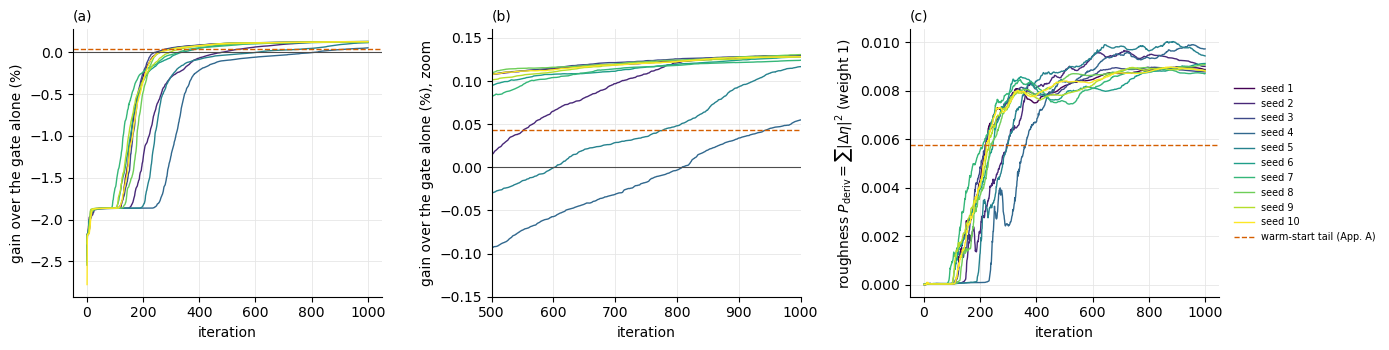

run,start F_pro,returned F_pro,gain (%),first it above gate alone,returned,iterations,wall (h),max|eta_1|,max|eta_2|,x pinned,deriv term (w 0.0625),deriv term at w 0.625,F gain over last 100 it (%)
seed 1,0.936544,0.961215,+0.1286,256,best_seen,1000,10.9,0.1002,0.1007,1.38%,5.56e-04,5.56e-03,+0.0015
seed 2,0.935603,0.961224,+0.1296,480,final,1000,10.8,0.1001,0.1007,1.19%,5.63e-04,5.63e-03,+0.0014
seed 3,0.935090,0.961218,+0.1290,242,best_seen,1000,10.7,0.1002,0.1007,1.94%,5.49e-04,5.49e-03,+0.0010
seed 4,0.934475,0.960478,+0.0549,808,final,1000,10.2,0.0997,0.1004,0.06%,6.08e-04,6.08e-03,+0.0210
seed 5,0.936801,0.961096,+0.1167,602,final,1000,10.8,0.1001,0.1008,0.12%,5.89e-04,5.89e-03,+0.0236
seed 6,0.936320,0.961210,+0.1281,335,final,1000,11.0,0.1001,0.1006,2.06%,5.70e-04,5.70e-03,+0.0040
seed 7,0.934789,0.961170,+0.1242,327,final,1000,11.0,0.1002,0.1007,2.00%,5.44e-04,5.44e-03,+0.0027
seed 8,0.934491,0.961235,+0.1307,261,final,1000,11.1,0.1001,0.1007,1.06%,5.67e-04,5.67e-03,+0.0027
seed 9,0.937023,0.961209,+0.1281,294,final,1000,11.1,0.1002,0.1007,1.31%,5.52e-04,5.52e-03,+0.0025
seed 10,0.932129,0.961210,+0.1282,258,best_seen,1000,10.9,0.1002,0.1007,1.00%,5.51e-04,5.51e-03,+0.0010


gate alone (Shirol, n_c 16): 0.959928


In [4]:
# Training curves of the ten noise-start runs, against the gate alone and the warm-start tail (Appendix A)
H = pd.read_csv("tables/tail_experiments_cold_heldout.csv")
ALONE = H[(H.kind == "alone") & (H.condition == "shirol")].F_pro.iloc[0]       # gate alone, Shirol set, n_c 16
WARM_F = RUNS["warm t2"][0]["F_pro"]
cmap = plt.get_cmap("viridis")
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
for k, label in enumerate(COLD):
    info, _ = RUNS[label]
    h = pd.DataFrame(info["history"])
    w = info["penalties"]["deriv"]
    kw = dict(color=cmap(k / (len(COLD) - 1)), lw=1.0, label=label)
    axs[0].plot(h.it, 100 * (h.F_pro - ALONE), **kw)
    axs[1].plot(h.it, 100 * (h.F_pro - ALONE), **kw)
    axs[2].plot(h.it, h.deriv / w, **kw)
for ax in axs[:2]:
    ax.axhline(0, color="0.3", lw=0.8)
    ax.axhline(100 * (WARM_F - ALONE), color=OKABE[4], lw=1.0, ls="--", label="warm-start tail (App. A)")
axs[1].set_xlim(500, 1000)
axs[1].set_ylim(-0.15, 0.16)
axs[2].axhline(RUNS["warm t2"][0]["terms"]["deriv"] / W_OLD, color=OKABE[4], lw=1.0, ls="--")
axs[0].set_ylabel(r"gain over the gate alone (%)")
axs[1].set_ylabel(r"gain over the gate alone (%), zoom")
axs[2].set_ylabel(r"roughness $P_{\rm deriv}=\sum|\Delta\eta|^2$ (weight 1)")
for ax, letter in zip(axs, "abc"):
    ax.set_xlabel("iteration")
    ax.set_title(f"({letter})", loc="left", fontsize=10)
    tidy(ax)
hh, ll = axs[1].get_legend_handles_labels()
axs[2].legend(hh, ll, frameon=False, fontsize=7, loc="center left", bbox_to_anchor=(1.02, 0.5))
fig.tight_layout()
fig.savefig("figures/tail_experiments_cold_training.png", dpi=150)
plt.show()


def first_above(h, level):
    above = h.index[h.F_pro > level]
    return int(h.it[above[0]]) if len(above) else None


rows = []
for label, (info, _) in list(RUNS.items()):
    if label not in COLD:
        continue
    h = pd.DataFrame(info["history"])
    rows.append({"run": label, "start F_pro": info["F_pro_start"], "returned F_pro": info["F_pro"],
                 "gain (%)": 100 * (info["F_pro"] - ALONE), "first it above gate alone": first_above(h, ALONE),
                 "returned": info["returned"], "iterations": info["nit"], "wall (h)": info["wall_s"] / 3600,
                 "max|eta_1|": info["max_eta_1"], "max|eta_2|": info["max_eta_2"], "x pinned": info["frac_preimage_pinned"],
                 "deriv term (w 0.0625)": info["terms"]["deriv"],
                 "deriv term at w 0.625": info["terms"]["deriv"] * W_OLD / info["penalties"]["deriv"],
                 "F gain over last 100 it (%)": 100 * (h.F_pro.iloc[-1] - h.F_pro.iloc[-101])})
wi = RUNS["warm t2"][0]
rows.append({"run": "warm t2 (App. A)", "start F_pro": wi["F_pro_start"], "returned F_pro": wi["F_pro"],
             "gain (%)": 100 * (wi["F_pro"] - ALONE), "returned": wi["returned"], "iterations": wi["nit"],
             "wall (h)": wi["wall_s"] / 3600, "max|eta_1|": wi["max_eta_1"], "max|eta_2|": wi["max_eta_2"],
             "x pinned": wi["frac_preimage_pinned"], "deriv term (w 0.0625)": wi["terms"]["deriv"] * 0.1,
             "deriv term at w 0.625": wi["terms"]["deriv"]})
runs3 = pd.DataFrame(rows)
display(runs3.style.hide(axis="index").format({
    "start F_pro": "{:.6f}", "returned F_pro": "{:.6f}", "gain (%)": "{:+.4f}", "wall (h)": "{:.1f}",
    "max|eta_1|": "{:.4f}", "max|eta_2|": "{:.4f}", "x pinned": "{:.2%}", "deriv term (w 0.0625)": "{:.2e}",
    "deriv term at w 0.625": "{:.2e}", "F gain over last 100 it (%)": "{:+.4f}", "first it above gate alone": "{:.0f}"},
    na_rep="-"))
print(f"gate alone (Shirol, n_c 16): {ALONE:.6f}")

**Figure 1 and Table 3.** The ten noise-start runs. **(a)** Every run starts 2.2–2.8 % below the gate alone (an almost
empty tail is 0.8 μs of waiting). Within 20 iterations every run reaches the same plateau, −1.87 % ($F_{\rm pro}$ 0.9413),
and sits there for 100–300 iterations. Seeds 1, 3, 6–10 leave it first, seeds 2, 5 and 4 later (seed 4 last, near
iteration 250). **(b)** The last 500 iterations. Eight runs end within 0.007 % of each other (+0.124 to +0.131 %),
three times the warm-start tail's +0.044 % (dashed). Seeds 5 (+0.117 %) and 4 (+0.055 %) are still climbing at the end,
+0.02 % per 100 iterations; the others gain 0.001–0.004 % over their last 100 iterations. **(c)** The roughness
$\sum|\Delta\eta|^2$ of the new tails is 0.0087–0.0097, 1.5–1.7 times the warm-start tail's 0.0057 (dashed). The weaker
penalty lets the waveforms move faster, and the optimizer uses it.

Every run used all 1000 iterations (none converged by the optimizer's own test), ends with both combs at the 0.1 cap,
and has 0.06–2.1 % of its optimizer variable at the box (Table 3). The derivative term of the new tails is 5.4–6.1e-4 in
the training cost. At the old weight it would be 5.4–6.1e-3, well above the warm-start tail's 3.6e-3: the old weight
would have charged these tails more than their gain in $F_{\rm pro}$.
*Symbols:* gain = $F_{\rm pro}$ − $F_{\rm pro}$(gate alone), Shirol set, $n_c = 16$; first it above gate alone = first iteration
with gain > 0; returned = "best seen" or "final" iterate; x pinned = share of the optimizer variable at its box; deriv
term = weighted derivative penalty of the returned tail; F gain over last 100 it = $F_{\rm pro}$(1000) − $F_{\rm pro}$(900).

## 5. Results: gain over the gate alone, seed by seed

Each tail is scored by `DGRAPE/fwm_tail_score.py` under its training noise and under noise and truncations it was not
trained on. Each condition has its own gate-alone and gate + idle reference (`tables/tail_experiments_cold_heldout.csv`).
The warm-start tail (Appendix A) is scored again in the same run for comparison. Figures 2 and 3 then compare the best
noise-start tail with the warm-start tail in time and in frequency.

In [5]:
COND = {"shirol": "Shirol, n_c 16 (training)", "shirol_nc_b": "Shirol, n_c 28", "train": "decay, n_c 16",
        "all_ch": "DGRAPE all_ch, n_c 16"}
alone5 = H[H.kind == "alone"].set_index("condition").F_pro
tr = H[H.kind == "trained"].copy()
tr["run"] = tr.tag.map(LABEL).replace({"warm t2": "warm t2 (App. A)"})
RUN_ORDER = list(COLD) + ["warm t2 (App. A)"]
F16 = tr[tr.condition == "shirol"].set_index("run").F_pro
gain = tr[tr.condition.isin(COND)].pivot(index="run", columns="condition", values="gain_vs_alone")[list(COND)] * 100
gain = gain.loc[RUN_ORDER].rename(columns=COND)
idle = tr[tr.condition == "shirol"].set_index("run").gain_vs_idle * 100
table4 = pd.concat({"F_pro": F16.loc[RUN_ORDER].to_frame("Shirol, n_c 16"), "gain vs gate alone (%)": gain,
                    "vs gate + idle (%)": idle.loc[RUN_ORDER].to_frame("Shirol, n_c 16")}, axis=1)
seed_rows = table4.loc[list(COLD)]
summ = pd.DataFrame({"mean": seed_rows.mean(), "std": seed_rows.std(ddof=1),
                     "max - min": seed_rows.max() - seed_rows.min()}).T
summ.index = [f"seeds 1-10 {k}" for k in summ.index]
table4 = pd.concat([table4, summ])
table4.loc["(gate alone F_pro)"] = [alone5["shirol"]] + [alone5[c] for c in COND] + [np.nan]
display(table4.style.format("{:+.3f}").format("{:.6f}", subset=pd.IndexSlice[:, [("F_pro", "Shirol, n_c 16")]])
        .format("{:.5f}", subset=pd.IndexSlice["(gate alone F_pro)", :], na_rep="-"))
f5 = F16.loc[[f"seed {s}" for s in range(1, 6)]]
print(f"seed rule (seeds 1-5, Shirol n_c 16): max - min = {f5.max() - f5.min():.2e} "
      f"-> {'> 1e-4: seeds 6-10 trained' if f5.max() - f5.min() > 1e-4 else '<= 1e-4: no more seeds'}")
fs = F16.loc[list(COLD)]
print(f"all ten: max - min = {fs.max() - fs.min():.2e}; without seed 4: {fs.drop('seed 4').max() - fs.drop('seed 4').min():.2e}")
d28 = (tr[tr.condition == "shirol_nc_b"].set_index("run").F_pro - F16).abs()
print(f"max |F_pro(n_c 28) - F_pro(n_c 16)| over the eleven tails: {d28.max():.1e}")

seed rule (seeds 1-5, Shirol n_c 16): max - min = 7.47e-04 -> > 1e-4: seeds 6-10 trained
all ten: max - min = 7.58e-04; without seed 4: 1.40e-04
max |F_pro(n_c 28) - F_pro(n_c 16)| over the eleven tails: 1.6e-08


**Table 4.** $F_{\rm pro}$ and gain of every tail, in %, by noise set and truncation; last column: gain over the gate + 0.8 μs
idle. Below the runs: mean, standard deviation and range over the ten seeds; last row: $F_{\rm pro}$ of the gate alone in
that column.

- **Every seed breaks even, at both truncations.** Gains under the Shirol set run from +0.055 % (seed 4) to **+0.131 %
  (seed 8, $F_{\rm pro}$ 0.961235 vs 0.959928)**; the median is +0.128 %. $n_c$ = 16 and 28 agree to 2e-8 for every tail.
- **Three times the warm-start tail:** the best seed beats it by +0.087 %. Eight seeds lie within 0.007 % of the best.
- **The seed rule fired:** over seeds 1–5 the range was 7.5e-4, above 1e-4, so seeds 6–10 were trained. All ten span
  7.6e-4; without seed 4, 1.4e-4. The range comes from the two slow seeds (4, 5), not from different solutions (Figure 2).
- **They are also better under the decay set**, the noise they were *not* trained with: +0.405 % for seed 8 against
  +0.321 % for the decay-trained tail. So the old derivative weight held back the decay-trained tail too.
- The step from the decay set to the Shirol set costs every tail the same 0.27–0.28 %, and `all_ch` costs 0.015 % more
  than the Shirol set. Against waiting instead (gate + idle), the best tail is +2.31 % ahead.

*Symbols:* gain = $F_{\rm pro}$(gate + tail) − $F_{\rm pro}$(reference), same noise and truncation, in percentage points;
$n_c = 16$ = gate run at 24 and cut, as in training; $n_c = 28$ = gate and tail both run there, no cut; std = sample
standard deviation over the ten seeds.

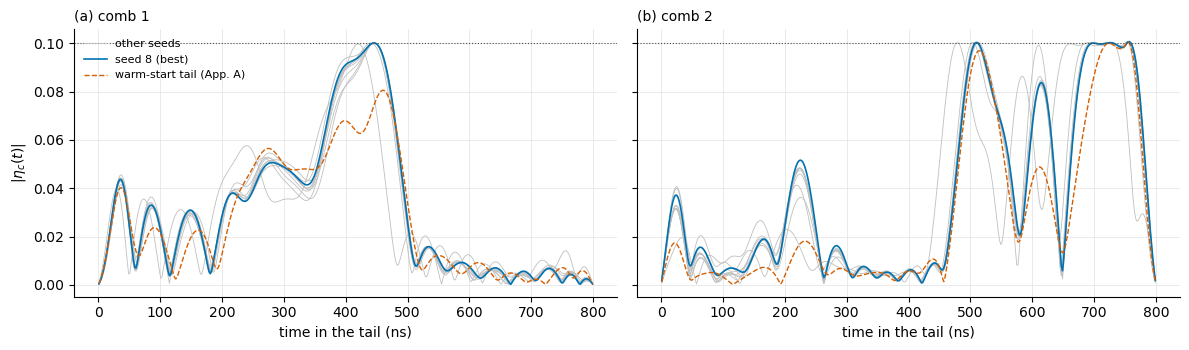

         comb 1 on (ns)  comb 1 off (ns)  comb 2 on (ns)  comb 2 off (ns)  mean |eta_1|  mean |eta_2|
seed 1           13.000          547.000           7.000          795.000         0.030         0.036
seed 2           13.000          551.000           5.000          795.000         0.030         0.037
seed 3           11.000          549.000           7.000          793.000         0.031         0.036
seed 4            9.000          763.000           7.000          793.000         0.029         0.037
seed 5           13.000          587.000          15.000          791.000         0.030         0.038
seed 6           13.000          581.000           7.000          793.000         0.030         0.037
seed 7           13.000          549.000           7.000          793.000         0.029         0.035
seed 8           13.000          551.000           7.000          795.000         0.031         0.037
seed 9           13.000          547.000           7.000          793.000         

In [6]:
# Waveforms: the best noise-start tail, every other seed (grey), and the warm-start tail
BEST = F16.loc[list(COLD)].idxmax()
t_ns = (np.arange(ft.n_steps(TAIL_US)) + 0.5) * DT * 1e3
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for c, ax in enumerate(axs):
    for label in COLD:
        if label != BEST:
            ax.plot(t_ns, np.abs(RUNS[label][1][:, c]), color="0.75", lw=0.6)
    ax.plot([], [], color="0.75", lw=0.6, label="other seeds")
    ax.plot(t_ns, np.abs(RUNS[BEST][1][:, c]), color=OKABE[0], lw=1.2, label=f"{BEST} (best)")
    ax.plot(t_ns, np.abs(RUNS["warm t2"][1][:, c]), color=OKABE[4], lw=1.0, ls="--", label="warm-start tail (App. A)")
    ax.axhline(ft.ETA_CAP, color="0.3", ls=":", lw=0.8)
    ax.set_xlabel("time in the tail (ns)")
    ax.set_title(f"({'ab'[c]}) comb {c + 1}", loc="left", fontsize=10)
    tidy(ax)
axs[0].set_ylabel(r"$|\eta_c(t)|$")
axs[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig("figures/tail_experiments_cold_waveforms.png", dpi=150)
plt.show()


def active_window(eta, frac=0.1):
    """first and last time (ns) where |eta_c| exceeds frac of its maximum"""
    out = []
    for c in range(2):
        a = np.abs(eta[:, c])
        on = np.where(a > frac * a.max())[0]
        out += [t_ns[on[0]], t_ns[on[-1]]]
    return out


win = pd.DataFrame({label: active_window(RUNS[label][1]) for label in list(COLD) + ["warm t2"]},
                   index=["comb 1 on (ns)", "comb 1 off (ns)", "comb 2 on (ns)", "comb 2 off (ns)"]).T
win["mean |eta_1|"] = [np.abs(RUNS[l][1][:, 0]).mean() for l in win.index]
win["mean |eta_2|"] = [np.abs(RUNS[l][1][:, 1]).mean() for l in win.index]
print(win.to_string(float_format="%.3f"))

**Figure 2. The waveforms.** $|\eta_c(t)|$ of the best noise-start tail (seed 8, blue), the nine other seeds (grey) and
the warm-start tail (orange, dashed). **All ten noise starts find the same tail as the warm start, only stronger.** The
shape is the one `FWM_tails.ipynb` §6 found: comb 1 works through the first half and ends in a shot at 400–500 ns,
then comb 2 empties the transmon in bursts at the cap from 480 ns to the end. What changes:

- comb 1's shot reaches the cap (0.100 at 445 ns, against 0.081),
- comb 2's burst at 615 ns is 0.084 instead of 0.049, and its early bump at 225 ns 0.052 instead of 0.018,
- comb 2 stays at the cap for 88 ns instead of 38 ns.

Seed 4, the slow one, differs most: its first comb-2 burst comes earlier (480 ns) and its comb 1 stays above 10 % of its
maximum until 763 ns (the others 547–587 ns). The table below the figure gives, per tail, the
first and last time each comb exceeds 10 % of its maximum and its mean amplitude.
*Symbols:* $|\eta_c(t)|$ comb amplitude (cap 0.1, dotted); time from the start of the tail.

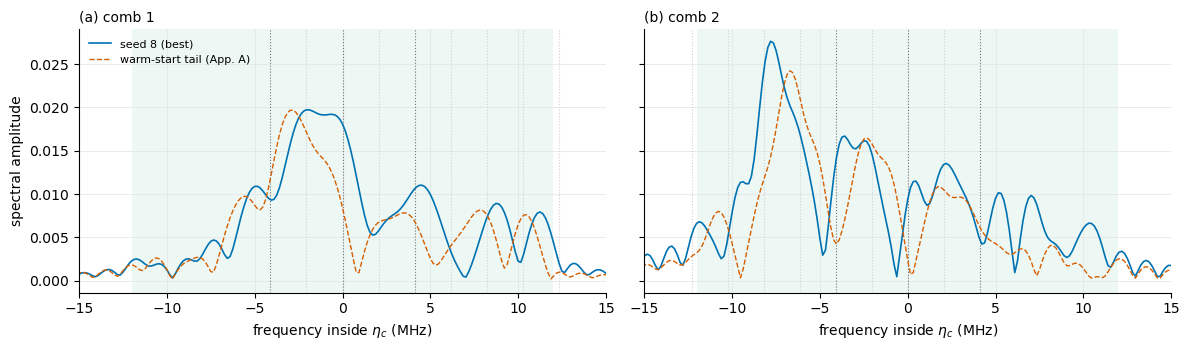

bare teeth inside eta_c:
 tooth n  comb 1 (MHz)  comb 2 (MHz)
       1         -4.14         +4.14
       3         +0.00         +0.01
       5         +4.12         -4.11
three largest peaks per comb and tail:
 comb     run  peak (MHz)  height  nearest repair tooth n  offset from it (MHz)
    1  seed 8      -2.031  +0.020                       3                -2.031
    1  seed 8      -0.625  +0.019                       3                -0.625
    1  seed 8      +4.531  +0.011                       5                +0.411
    1 warm t2      -2.812  +0.020                       1                +1.323
    1 warm t2      -5.625  +0.010                       1                -1.490
    1 warm t2      +7.812  +0.008                       5                +3.693
    2  seed 8      -7.812  +0.028                       5                -3.706
    2  seed 8      -3.594  +0.017                       5                +0.513
    2  seed 8      -2.500  +0.016                       5           

In [7]:
# Spectra of the best noise-start tail and of the warm-start tail (frequency inside eta_c = offset from the frame carrier)
from scipy.signal import find_peaks

PAD = 8                                                    # zero padding: smoother curves, resolution stays 1/T
off = ft.tooth_offsets(16, ft.N_REF, fwm.FULL_PATHS)
teeth_mhz = [dict(zip(off["paths"], off[f"comb{c}"] / (2 * np.pi))) for c in (1, 2)]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
peaks = []
for c, ax in enumerate(axs):
    for n, x in zip(off["paths"], off[f"comb{c + 1}"] / (2 * np.pi)):
        ax.axvline(x, color="0.45" if n in ft.REPAIR_PATHS else "0.82", lw=0.8, ls=":")
    ax.axvspan(*ft.ETA_BAND, color=OKABE[2], alpha=0.07, lw=0)
    for k, label in enumerate([BEST, "warm t2"]):
        eta = RUNS[label][1][:, c]
        n_pad = PAD * len(eta)
        freq = np.fft.fftshift(np.fft.fftfreq(n_pad, DT))  # MHz
        spec = np.abs(np.fft.fftshift(np.fft.fft(eta, n_pad))) / len(eta)
        ax.plot(freq, spec, color=[OKABE[0], OKABE[4]][k], lw=1.2 if k == 0 else 1.0, ls="-" if k == 0 else "--",
                label=f"{label} (best)" if k == 0 else "warm-start tail (App. A)")
        idx, _ = find_peaks(spec, height=0.2 * spec.max())
        for i in idx[np.argsort(spec[idx])[::-1]][:3]:      # the three largest
            near = min(ft.REPAIR_PATHS, key=lambda n: abs(teeth_mhz[c][n] - freq[i]))
            peaks.append({"comb": c + 1, "run": label, "peak (MHz)": freq[i], "height": spec[i],
                          "nearest repair tooth n": near, "offset from it (MHz)": freq[i] - teeth_mhz[c][near]})
    ax.set_xlim(-15, 15)
    ax.set_xlabel(r"frequency inside $\eta_c$ (MHz)")
    ax.set_title(f"({'ab'[c]}) comb {c + 1}", loc="left", fontsize=10)
    tidy(ax)
axs[0].set_ylabel("spectral amplitude")
axs[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig("figures/tail_experiments_cold_spectra.png", dpi=150)
plt.show()
tooth_tab = pd.DataFrame({"tooth n": off["paths"], "comb 1 (MHz)": off["comb1"] / (2 * np.pi),
                          "comb 2 (MHz)": off["comb2"] / (2 * np.pi)})
print("bare teeth inside eta_c:")
print(tooth_tab[tooth_tab["tooth n"].isin(ft.REPAIR_PATHS)].to_string(index=False, float_format="%+.2f"))
print("three largest peaks per comb and tail:")
print(pd.DataFrame(peaks).to_string(index=False, float_format="%+.3f"))

**Figure 3. Spectra of the best noise-start tail and the warm-start tail.** **(a)** comb 1, **(b)** comb 2. The frequency is
measured inside $\eta_c$, i.e. from the frame carrier (comb-1 tooth 2 → 3). Dotted lines: the bare teeth, darker for the
three repair teeth $n$ = 1, 3, 5. Green: the ±12 MHz band. The FFT is zero-padded 8× for smooth curves; the true
resolution is 1/0.8 μs = 1.25 MHz, so features closer than that blend.

- **The two spectra have the same structure**, as the waveforms suggest. Comb 2's main peak moves from −6.7 to −7.8 MHz
  and its second peak from −2.3 to about −3.6 / −2.5 MHz (a double peak now). Comb 1's broad peak widens from
  −2.8 MHz to a plateau from −2.0 to −0.6 MHz, and it gains a peak at +4.5 MHz, near tooth 5 (+4.1 MHz).
- Both moves go the way the pump Stark shift goes (comb 2 down, comb 1 up; `fwm_tail.teeth_stark_shifts`), and the new
  tail has larger amplitudes, so larger Stark shifts. At 2π·538 MHz·$|\xi|^2$, $|\xi|$ = 0.08 instead of 0.07 moves a
  line by 3.4 instead of 2.6 MHz. This is a reading of the spectra, not a fit.
- The "nearest repair tooth" column of the printed table is only the closest of teeth 1, 3, 5 to each peak. For shifted
  lines several MHz from a tooth it can name a neighbour.

*Symbols:* $\eta_c$ = comb-$c$ waveform; spectral amplitude = $|{\rm FFT}(\eta_c)|/N$ with $N$ = 400 samples; tooth $n$ =
the comb line that serves the repair $n{-}1 \to n$ (comb 1) or empties $|n, f\rangle$ into the readout (comb 2);
$\xi$ = pump amplitude in the lab frame ($|\xi_c| = |\eta_c|$).

## 6. Where the extra gain comes from

We score the gate alone and gate + each tail with only one group of Shirol's jump operators on
(`DGRAPE/tail_experiments_channels.py` → `tables/tail_experiments_cold_channels.csv`). "Closed" has no jumps. Then the
same tails are scored with the pump strength off by ±10 %.

,gate alone: cost (%),warm t2: cost (%),seed 8: cost (%),warm t2: gain change (%),seed 8: gain change (%),seeds 1-10 mean: gain change (%),seeds 1-10 max - min (%)
group,,,,,,,
closed,+0.000,+0.000,+0.000,-0.014,-0.010,-0.009,+0.003
photon loss,+2.402,+1.624,+1.576,+0.779,+0.826,+0.819,+0.048
other decay,+0.781,+1.032,+1.048,-0.251,-0.267,-0.266,+0.021
transmon heating,+0.101,+0.154,+0.154,-0.054,-0.053,-0.053,+0.000
storage heating,+0.020,+0.034,+0.034,-0.014,-0.014,-0.014,+0.000
transmon dephasing,+0.383,+0.568,+0.568,-0.185,-0.185,-0.185,+0.003
storage dephasing,+0.238,+0.266,+0.265,-0.028,-0.027,-0.028,+0.000
all,+3.877,+3.819,+3.736,+0.057,+0.140,+0.129,+0.078


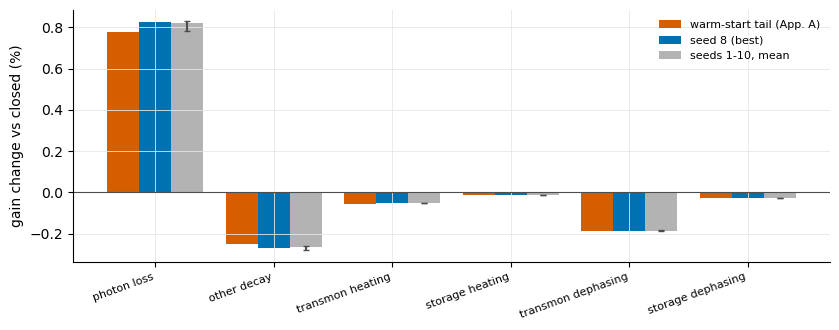

In [8]:
C = pd.read_csv("tables/tail_experiments_cold_channels.csv")
C["run"] = C.tag.map({**LABEL, "alone": "gate alone"})
GROUP_ORDER = ["closed", "photon loss", "other decay", "transmon heating", "storage heating",
               "transmon dephasing", "storage dephasing", "all"]
closed = C[C.group == "closed"].set_index("run").F_pro
C["cost (%)"] = 100 * (C.run.map(closed) - C.F_pro)
cost6 = C.pivot(index="group", columns="run", values="cost (%)").loc[GROUP_ORDER]
gain6 = (C[C.run != "gate alone"].pivot(index="group", columns="run", values="gain_vs_alone") * 100).loc[GROUP_ORDER]
gain6 = gain6 - gain6.loc["closed"]
gain6.loc["closed"] = (C[(C.run != "gate alone") & (C.group == "closed")].set_index("run").gain_vs_alone * 100)
seed_mean = gain6[list(COLD)].mean(axis=1)
seed_rng = gain6[list(COLD)].max(axis=1) - gain6[list(COLD)].min(axis=1)
table5 = pd.DataFrame({"gate alone: cost (%)": cost6["gate alone"], "warm t2: cost (%)": cost6["warm t2"],
                       f"{BEST}: cost (%)": cost6[BEST],
                       "warm t2: gain change (%)": gain6["warm t2"], f"{BEST}: gain change (%)": gain6[BEST],
                       "seeds 1-10 mean: gain change (%)": seed_mean, "seeds 1-10 max - min (%)": seed_rng})
display(table5.style.format("{:+.3f}"))
fig, ax = plt.subplots(figsize=(8.5, 3.4))
groups = GROUP_ORDER[1:-1]
w = 0.27
for k, (col, lab, colr) in enumerate([("warm t2", "warm-start tail (App. A)", OKABE[4]), (BEST, f"{BEST} (best)", OKABE[0])]):
    ax.bar(np.arange(len(groups)) + (k - 1) * w, gain6.loc[groups, col], w, color=colr, label=lab)
ax.bar(np.arange(len(groups)) + w, seed_mean.loc[groups], w, color="0.7", label="seeds 1-10, mean",
       yerr=[seed_mean.loc[groups] - gain6.loc[groups, list(COLD)].min(axis=1),
             gain6.loc[groups, list(COLD)].max(axis=1) - seed_mean.loc[groups]], capsize=2, ecolor="0.3")
ax.axhline(0, color="0.3", lw=0.8)
ax.set_xticks(np.arange(len(groups)))
ax.set_xticklabels(groups, rotation=20, ha="right", fontsize=8)
ax.set_ylabel("gain change vs closed (%)")
ax.legend(frameon=False, fontsize=8)
tidy(ax)
fig.tight_layout()
fig.savefig("figures/tail_experiments_cold_channels.png", dpi=150)
plt.show()

**Table 5 and Figure 4.** Left three columns of Table 5: the infidelity each channel group adds on its own (closed
$F_{\rm pro}$ minus $F_{\rm pro}$ with that group only), in %. Right four columns and Figure 4: how that group changes the
tail's gain compared with the closed system. The "closed" row of the gain columns is the closed gain itself.

- **All of the extra gain is better photon-loss repair.** With loss alone, the best tail gains +0.826 % over closed, the
  warm-start tail +0.779 %: +0.047 %. The loss cost of gate + tail falls from 1.62 % to 1.58 % (gate alone 2.40 %).
- **Everything else costs the new tails as much as the old one, or slightly more.** Readout and transmon decay ("other
  decay") −0.267 % against −0.251 %: the stronger shot puts more population in $|f\rangle$ and the readout. Transmon
  dephasing (−0.185 %), heating and storage channels are the same to 0.001 %. A shorter or later shot did not appear.
- The closed error of the tail fell slightly (−0.010 % against −0.014 %).
- All channels together: +0.140 % against +0.057 % over closed. As for the warm-start tail, the groups do not add up
  (one at a time they give +0.28 % for the best tail).
- The ten seeds agree to 0.003 % in every single group except photon loss (0.048 %) and other decay (0.021 %), where the slow
  seed 4 sits low.

*Symbols:* closed = no jump operators; group names as in Table 1 (other decay = $\kappa_r$ + transmon $T_1$, heating includes
the pumps' extra heating); all = Shirol full set; gain change = gain(group only) − gain(closed).

In [9]:
# Robustness (decay set, n_c 16): pump strength +-10 %, and the closed / photon-loss-only scores
ROB = {"closed": "closed", "loss_only": "photon loss only", "eta_x0.9": "pump x 0.9", "eta_x1.1": "pump x 1.1"}
rob = tr[tr.condition.isin(ROB)].pivot(index="run", columns="condition", values="gain_vs_alone")[list(ROB)] * 100
rob = rob.loc[RUN_ORDER].rename(columns=ROB)
rob.loc["seeds 1-10 mean"] = rob.loc[list(COLD)].mean()
display(rob.style.format("{:+.3f}"))

condition,closed,photon loss only,pump x 0.9,pump x 1.1
run,,,,
seed 1,-0.010,+0.813,-17.540,-20.752
seed 2,-0.010,+0.818,-17.611,-20.978
seed 3,-0.010,+0.816,-19.029,-22.413
seed 4,-0.008,+0.772,-14.492,-17.060
seed 5,-0.007,+0.806,-16.103,-19.042
seed 6,-0.009,+0.811,-15.979,-19.051
seed 7,-0.010,+0.810,-14.758,-17.855
seed 8,-0.010,+0.817,-18.210,-21.432
seed 9,-0.010,+0.816,-17.860,-21.061


**Table 6. Robustness**, decay set, $n_c = 16$, gain over the gate alone in %. Closed and photon loss only repeat Table 5's
picture under the decay set (+0.82 % against +0.77 % with loss only). **The new tails are more fragile to the pump
strength:** a 10 % error costs them 14–19 % (×0.9) and 17–22 % (×1.1), against 10 % and 13 % for the warm-start tail.
The whole break-even margin (0.13 %) is less than 1 % of that loss. A likely reason: the stronger shot has larger
Stark shifts, so its lines move more when the pump strength changes.
*Symbols:* pump × 0.9 / 1.1 = both combs' $\eta$ scaled by that factor after training; closed = no jumps; photon loss only =
$\kappa_a$ as the only jump.

## 7. Verdict

The cell below applies the break-even rule of §1 to Table 4.

In [10]:
# The two rules of section 1, checked on the numbers above
g16 = tr[tr.condition == "shirol"].set_index("run").gain_vs_alone
g28 = tr[tr.condition == "shirol_nc_b"].set_index("run").gain_vs_alone
print(f"best noise-start tail: {BEST}")
print(f"gain vs gate alone, Shirol full set: n_c 16 (cut) {100 * g16[BEST]:+.4f} %, n_c 28 {100 * g28[BEST]:+.4f} %")
seeds = list(COLD)
print(f"over the ten seeds: n_c 16 gain {100 * g16[seeds].min():+.4f} to {100 * g16[seeds].max():+.4f} %, "
      f"median {100 * g16[seeds].median():+.4f} %; seeds breaking even at both n_c: "
      f"{sum((g16[seeds] > 0) & (g28[seeds] > 0))} of {len(seeds)}")
print(f"warm-start tail (App. A): {100 * g16['warm t2 (App. A)']:+.4f} %;  best minus warm: "
      f"{100 * (g16[BEST] - g16['warm t2 (App. A)']):+.4f} %")
print("BREAKS EVEN" if min(g16[BEST], g28[BEST]) > 0 else "DOES NOT BREAK EVEN")

best noise-start tail: seed 8
gain vs gate alone, Shirol full set: n_c 16 (cut) +0.1307 %, n_c 28 +0.1307 %
over the ten seeds: n_c 16 gain +0.0549 to +0.1307 %, median +0.1282 %; seeds breaking even at both n_c: 10 of 10
warm-start tail (App. A): +0.0436 %;  best minus warm: +0.0871 %
BREAKS EVEN


**Verdict: the tail breaks even, now by +0.131 %.** With every one of Shirol's error channels on, in the gate as well as
the tail, gate + 0.8 μs tail (seed 8) beats the gate alone by **+0.131 %** ($F_{\rm pro}$ 0.96124 vs 0.95993), at the
training truncation and held out at $n_c$ = 28. All ten seeds break even (+0.055 to +0.131 %); eight lie within
0.007 % of the best. The margin is three times the warm-start tail's +0.044 %, and still far smaller than the cost of a
10 % pump error (14–22 %).

**Conclusions**

1. **The derivative penalty was what held the tail back.** With its weight 10 times smaller, every noise start climbs
   past the warm-start tail. Since all ten starts end on the same waveform as the warm start (Figure 2), only stronger,
   the start was not the obstacle: the old weight was. The new tails are better under the decay set as well (+0.405 %
   against +0.321 %).
2. **The extra 0.09 % is better photon-loss repair** (+0.047 % with loss alone), from a comb-1 shot at the cap and
   stronger comb-2 bursts. Every other channel costs the same as before or slightly more. The noise-aware training did
   not find a tail that avoids transmon dephasing.
3. **The price is smoothness and robustness.** The waveforms are 1.5–1.7 times rougher, and a 10 % pump error now costs
   14–22 % instead of 10–13 %.
4. **The seed rule fired, but the seeds agree.** The 0.076 % range comes from two slow seeds (4 and 5) that were still
   climbing at iteration 1000. The other eight are one solution to 0.007 %.

**Next steps (not run)**

- **Separate the two changes**: warm-start from the decay-trained tail with the weight ÷10 (cheap, ~1/3 of the iterations),
  to confirm the weight alone gives the gain. Also retrain under the decay set at ÷10, since the decay-trained tail is
  the reference of `FWM_tails.ipynb`.
- **Resume seeds 4 and 5** (`--start pulses/dgrape/xe_X_tail_estg_T08_shirol_d01_s4.npy`, and s5) to see whether they reach the same +0.13 %.
- **No derivative penalty at all**, or ÷100, to find where the gain stops; check the roughness against what the
  hardware can follow.
- **Robust training over pump strength ±10 %**: the margin is now 0.13 %, still far below the pump sensitivity.
- **Shorter tails** (0.5–0.6 μs), where the non-loss costs are smaller.

## Appendix A. The warm-start runs (first attempt, 2026-11-11/12)

Two runs started from the decay-trained 0.8 μs tails (`xe_X_tail_estg_T08_{t2,z}.npy`), switched the Shirol set on and
trained 600 iterations at the old derivative weight (0.625), 3.9 h each:

```
python DGRAPE/train_fwm_tail.py --start pulses/dgrape/xe_X_tail_estg_T08_t2.npy --tag X_tail_estg_T08_shirol_t2 \
    --channels shirol --tail-us 0.8 --max-iter 600 --gate-pulse pulses/dgrape/u_X_est_err_closed_s24.npy \
    --gate-n-c 24 --n-c 16 --n-jobs 3 --outdir ~/fwm_runs/tails_shirol        # and the same with z
```

Outputs: `pulses/dgrape/*X_tail_estg_T08_shirol_{t2,z}*`, `tables/tail_experiments_{heldout,channels}.csv`.

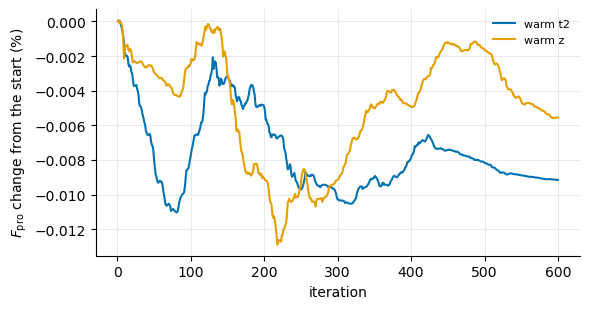

run,start F_pro,returned F_pro,last iterate F_pro,returned,deriv term start -> end,gain n_c 16 (%),gain n_c 28 (%)
warm t2,0.960364,0.960364,0.960272,best_seen,3.59e-03 -> 3.27e-03,+0.0436,+0.0436
warm z,0.960326,0.960326,0.960270,best_seen,3.58e-03 -> 3.27e-03,+0.0398,+0.0398


In [11]:
# Appendix A: the warm-start runs (start = the decay-trained tails, derivative weight 0.625, 600 iterations)
HA = pd.read_csv("tables/tail_experiments_heldout.csv")
fig, ax = plt.subplots(figsize=(6, 3.2))
rowsA = []
for k, label in enumerate(WARM):
    info, _ = RUNS[label]
    h = pd.DataFrame(info["history"])
    ax.plot(h.it, 100 * (h.F_pro - info["F_pro_start"]), color=OKABE[k], label=label)
    gA = HA[(HA.tag == WARM[label]) & HA.condition.isin(["shirol", "shirol_nc_b"])].set_index("condition").gain_vs_alone
    rowsA.append({"run": label, "start F_pro": info["F_pro_start"], "returned F_pro": info["F_pro"],
                  "last iterate F_pro": info["history"][-1]["F_pro"], "returned": info["returned"],
                  "deriv term start -> end": f"{info['history'][0]['deriv']:.2e} -> {info['history'][-1]['deriv']:.2e}",
                  "gain n_c 16 (%)": 100 * gA["shirol"], "gain n_c 28 (%)": 100 * gA["shirol_nc_b"]})
ax.set_xlabel("iteration")
ax.set_ylabel(r"$F_{\rm pro}$ change from the start (%)")
ax.legend(frameon=False, fontsize=8)
tidy(ax)
fig.tight_layout()
fig.savefig("figures/tail_experiments_training.png", dpi=150)
plt.show()
display(pd.DataFrame(rowsA).style.hide(axis="index").format(
    {"start F_pro": "{:.6f}", "returned F_pro": "{:.6f}", "last iterate F_pro": "{:.6f}",
     "gain n_c 16 (%)": "{:+.4f}", "gain n_c 28 (%)": "{:+.4f}"}))

**Figure A1 and Table A1.** $F_{\rm pro}$ during the warm-start runs, from their start. It never rose more than 7e-7 above
the start, then fell by up to 0.013 % and ended 0.006 % (z) to 0.009 % (t2) below it. The cost still fell, because the
roughness fell (derivative term 3.59e-3 → 3.27e-3): **at the old weight, smoothing paid more than fidelity.** The trainer
returned iteration 1, so the "warm-start tails" are the decay-trained tails, changed by at most 1e-4 in $\eta$. They
break even by +0.044 % (t2) and +0.040 % (z), the same at $n_c$ = 16 and 28, and the channel breakdown (old Table 6,
`tables/tail_experiments_channels.csv`) gave the numbers of the warm t2 column of Table 5. The figures of that version of
this notebook (`figures/tail_experiments_{waveforms,spectra,channels}.png`) stay on disk; Figures 2–4 here replace them.
*Symbols:* $F_{\rm pro}$ at $n_c = 16$, Shirol set; gain at $n_c$ 16 / 28 = over the gate alone, Shirol set; deriv term =
weighted derivative penalty (weight 0.625).